# **Einflussfaktoren auf den Filialumsatz von Rossmann**

***1. Ausgangslage und Zielsetzung***
Im Einzelhandel schwankt der Tagesumsatz einer Filiale stark. Für Unternehmen wie Rossmann ist es wichtig
zu wissen, welche Faktoren den Umsatz beeinflussen, etwa um Rabattaktionen gezielt zu planen oder
Standorte besser zu bewerten. Ziel des Projekts ist es, mit Python in einem Jupyter Notebook zu
analysieren, wie Rabattaktionen und Filialmerkmale mit dem Umsatz zusammenhängen, und die Ergebnisse
zu visualisieren.

***2. Datenbeschreibung***
Wir nutzen den Datensatz Rossmann Store Sales von der Plattform Kaggle
(https://www.kaggle.com/competitions/rossmann-store-sales/overview). Er enthält echte Verkaufsdaten
von 1.115 Rossmann-Filialen in Deutschland aus dem Zeitraum 01.01.2013 bis 31.07.2015. Die Daten liegen
in zwei Tabellen vor, die über die Filialnummer (Store) verbunden werden können.

***3. Forschungsfragen***
*   FF1: Wie stark erhöht eine Rabattaktion (Promo) den Tagesumsatz einer Rossmann-Filiale, und unterscheidet sich diese Wirkung je nach Wochentag?
*   FF2: Wie hängen Filialtyp, Sortiment und Entfernung zur Konkurrenz mit dem Umsatz und dem Umsatz pro
Kunde zusammen?

FF1 nutzt die Tagesdaten. Für FF2 verbinden wir beide Tabellen über die Filialnummer, damit jeder
Tagesumsatz den Merkmalen seiner Filiale zugeordnet werden kann.

***4. Vorgehen und Werkzeuge***
1. Datenaufbereitung: Tabellen laden, bereinigen und für FF2 über Store zusammenführen.
2. Explorative Analyse: Umsätze nach Promo, Wochentag, Filialtyp, Sortiment und
Konkurrenzentfernung vergleichen.
3. Auswertung: Mittelwertvergleiche und Korrelationsanalyse, um die Stärke der Zusammenhänge zu
prüfen.
4. Visualisierung: Ergebnisse als Diagramme (z. B. Balken- und Boxplots) im Notebook darstellen.

In [1]:
import pandas as pd
import numpy as np

# **1. Datenaufbereitung**

## CSV-Dateien importieren und laden


In [2]:
store = pd.read_csv('store.csv')  # Filialdaten
store.head()

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [3]:
sales = pd.read_csv('train.csv')  # Tages- & Verkaufsdaten
sales.head()

/tmp/ipykernel_23844/4143677051.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv('train.csv')  # Tages- & Verkaufsdaten


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


Benötigte Spalten für unsere Forschungsfragen / Aufbereitung der Daten im Hinblick auf die Forschungsfragen:
*   Store
*   StoreType
*   Assortment
*   CompetitionDistance
*   Promo2
*   DayOfWeek
*   Sales
*   Customers
*   Open
*   Promo

## Überblick über die Daten verschaffen

### Technischer Überblick über die Daten: Datentypen, Aufbau, fehlende Daten, etc.

In [4]:
sales.info()
store.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  object
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(2)
memory usage: 69.8+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1115 entries, 0 to 1114
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Store                      1115 non-null   int64  
 1   StoreType                  1115 non-null   object 
 2   Assort

### Nach fehlenden Werten in jeweiligen Spalten suchen

In [5]:
store.isnull().sum()

,0
Store,0
StoreType,0
Assortment,0
CompetitionDistance,3
CompetitionOpenSinceMonth,354
CompetitionOpenSinceYear,354
Promo2,0
Promo2SinceWeek,544
Promo2SinceYear,544
PromoInterval,544


--> CompetitionDistance hat 3 Zeilen mit dem Wert NULL: In 3 Zeilen fehlt also die Entfernung zum nächsten Konkurrenten. Dies liegt wahrscheinlich daran, dass die entsprechenden Informationen nicht in das System eingegeben wurden. Die fehlenden Werte werden wir daher durch den Median ersetzen. Die Angaben zum Bestehen der Konkurrenz (CompetitionOpenSince...) sowie zeitliche Einordnungen zur Rabattaktionen (Promo2Since...) sind für die Forschungsfrage irrelevant.

In [6]:
sales.isnull().sum()

,0
Store,0
DayOfWeek,0
Date,0
Sales,0
Customers,0
Open,0
Promo,0
StateHoliday,0
SchoolHoliday,0


--> In der Tabelle Sales gibt es keine fehlenden Werte

### Überprüfung von Duplikaten
Doppelte Zeilen würden Berechnungen verfälschen

In [7]:
# .duplicated() geht Zeile für Zeile durch das die Tabellen und prüft, ob exakt dieselbe Zeile weiter oben schon einmal vorkam
print('Duplikate sales:', sales.duplicated().sum())
print('Duplikate store:', store.duplicated().sum())

Duplikate sales: 0
Duplikate store: 0


--> keine Duplikate vorhanden

## Daten bereinigen und aufbereiten

### Geschlossene Filialen entfernen

In [8]:
sales['Open'].value_counts()  # Geöffnete und geschlossene Zeiten zählen.

,count
Open,
1,844392
0,172817


In [9]:
sales = sales[sales['Open'] == 1].copy()  # Filtert den Datensatz so, dass ausschließlich geöffnete Filialen (Open == 1) behalten werden, und speichert das Ergebnis als neue Kopie.
                                          #   Dieser Schritt verhindert, dass Filialen mit 0 € Umsatz (weil sie geschlossen waren) Vergleiche verfälschen.

In [10]:
sales = sales.drop(columns=['Open'])  # Löscht die Spalte 'Open' endgültig aus dem Datensatz. Da nach dem vorherigen Filter-Schritt ohnehin nur noch
                                      #   geöffnete Filialen im Datensatz stehen, wird diese Information nicht mehr benötigt.

### Sales und Customers kontrollieren

In [11]:
sales[(sales['Sales'] == 0) | (sales['Customers'] == 0)].head(5)  # Überprüfung der Zeilen mit Sales = 0 ODER Customers = 0 trotz geöffneter Filiale.

,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday
86825,971,5,2015-05-15,0,0,0,0,1
142278,674,4,2015-03-26,0,0,0,0,0
196938,699,4,2015-02-05,0,0,1,0,0
322053,708,3,2014-10-01,0,0,1,0,0
330176,357,1,2014-09-22,0,0,0,0,0


In [12]:
sales[(sales['Sales'] == 0) | (sales['Customers'] == 0)].shape  # Ermittlung Anzahl der Zeilen mit Sales = 0 ODER Customers = 0 trotz geöffneter Filiale.

(54, 8)

In [13]:
sales = sales[~((sales['Sales'] == 0) & (sales['Customers'] == 0))].copy()  # Zeilen werden behalten, außer die, die Sales = 0 UND Customers = 0 enthalten.

In [14]:
sales[(sales['Sales'] == 0) | (sales['Customers'] == 0)].head() # Erneute Überprüfung der Zeilen mit Sales = 0 ODER Customers = 0.

,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday
478649,1100,2,2014-04-29,0,3,1,0,0
889932,948,4,2013-04-25,0,5,1,0,0


--> Am Index 478649 waren bspw. 3 Kunden im Laden, die alle nichts gekauft haben. Diese Daten bleiben allerdings dabei, um die späteren Berechnungen nicht zu verfälschen.

### Fehlende Werte in Spalte ComeptionDistance füllen

In [15]:
store['CompetitionDistance'].describe() # Median der Werte in der Spalte CompetitionDistance ermitteln.

,CompetitionDistance
count,1112.000000
mean,5404.901079
std,7663.174720
min,20.000000
25%,717.500000
50%,2325.000000
75%,6882.500000
max,75860.000000


--> Median: 2325

In [16]:
store['CompetitionDistance'] = store['CompetitionDistance'].fillna(store['CompetitionDistance'].median())  # Fehlende Werte in der Spalte CompetitionDistance durch den Median ersetzen.

In [17]:
store['CompetitionDistance'].isnull().sum() # Überprüfung, ob noch leere Zellen vorhanden sind

np.int64(0)

--> keine leeren Zellen mehr

### Spalte für Umsatz pro Kunde erstellen

In [18]:
sales['Customers'].isnull().sum() # Überprüfung, ob ein Wert in der Spalte Customers NULL entspricht. Das würde sonst im Folgenden Probleme für die Formel ergeben.

np.int64(0)

In [19]:
sales['SalesPerCustomer'] = sales['Sales'] / sales['Customers'] # Spalte erstellen und Umsatz pro Kunde berechnen
sales.head()  # Anzeigen zum Überprüfen

,Store,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday,SalesPerCustomer
0,1,5,2015-07-31,5263,555,1,0,1,9.482883
1,2,5,2015-07-31,6064,625,1,0,1,9.702400
2,3,5,2015-07-31,8314,821,1,0,1,10.126675
3,4,5,2015-07-31,13995,1498,1,0,1,9.342457
4,5,5,2015-07-31,4822,559,1,0,1,8.626118


--> Hat funktioniert

### Tabellen verbinden

In [20]:
store_index = store.set_index('Store') # Spalte 'Store' aus Tabelle Store wird als Index gesetzt
display(store_index)
type(store_index)

,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
Store,,,,,,,,,
1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN


pandas.core.frame.DataFrame

In [21]:
sales_index = sales.set_index('Store') # Spalte 'Store' aus Tabelle Sales wird als Index gesetzt
display(sales_index)
type(sales_index)

,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday,SalesPerCustomer
Store,,,,,,,,
1,5,2015-07-31,5263,555,1,0,1,9.482883
2,5,2015-07-31,6064,625,1,0,1,9.702400
3,5,2015-07-31,8314,821,1,0,1,10.126675
4,5,2015-07-31,13995,1498,1,0,1,9.342457
5,5,2015-07-31,4822,559,1,0,1,8.626118
...,...,...,...,...,...,...,...,...
682,2,2013-01-01,3375,566,0,a,1,5.962898
733,2,2013-01-01,10765,2377,0,a,1,4.528818
769,2,2013-01-01,5035,1248,0,a,1,4.034455


pandas.core.frame.DataFrame

Tabellen Store und Sales mit einem Join verbinden.

In [22]:
store_sales_joined = store_index.join(sales_index, how='inner', on='Store') # Inner Join behält nur Treffer, die in beiden Tabellen existieren. Maximale Datenqualität, keine neuen NULL-Werte.
display(store_sales_joined)                                                 # on='Store': Store ist der gemeinsame Schlüssel beider Tabellen (Primary Key) und dient als Verbindungselement.

,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,DayOfWeek,Date,Sales,Customers,Promo,StateHoliday,SchoolHoliday,SalesPerCustomer
Store,,,,,,,,,,,,,,,,,
1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,5,2015-07-31,5263,555,1,0,1,9.482883
1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,4,2015-07-30,5020,546,1,0,1,9.194139
1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,3,2015-07-29,4782,523,1,0,1,9.143403
1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,2,2015-07-28,5011,560,1,0,1,8.948214
1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN,1,2015-07-27,6102,612,1,0,1,9.970588
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1115,d,c,5350.0,NaN,NaN,1,22.0,2012.0,"Mar,Jun,Sept,Dec",1,2013-01-07,6905,471,1,0,1,14.660297
1115,d,c,5350.0,NaN,NaN,1,22.0,2012.0,"Mar,Jun,Sept,Dec",6,2013-01-05,4771,339,0,0,1,14.073746
1115,d,c,5350.0,NaN,NaN,1,22.0,2012.0,"Mar,Jun,Sept,Dec",5,2013-01-04,4540,326,0,0,1,13.926380


Erstellung der finalen Tabelle, auf deren Basis die Analysen und Auswertungen geschehen.

*   Es werden nur folgende Spalten gewählt, um den Umfang dieses Projekts in einem angemessenen Rahmen zu halten, bzw. benötigen wir nur diese Spalten für die Beantwortung unserer Forschungsfragen.



In [23]:
rossmann = store_sales_joined[['StoreType', 'Assortment', 'CompetitionDistance', 'Promo', 'Promo2', 'DayOfWeek', 'Sales', 'Customers', 'SalesPerCustomer']]
rossmann

,StoreType,Assortment,CompetitionDistance,Promo,Promo2,DayOfWeek,Sales,Customers,SalesPerCustomer
Store,,,,,,,,,
1,c,a,1270.0,1,0,5,5263,555,9.482883
1,c,a,1270.0,1,0,4,5020,546,9.194139
1,c,a,1270.0,1,0,3,4782,523,9.143403
1,c,a,1270.0,1,0,2,5011,560,8.948214
1,c,a,1270.0,1,0,1,6102,612,9.970588
...,...,...,...,...,...,...,...,...,...
1115,d,c,5350.0,1,1,1,6905,471,14.660297
1115,d,c,5350.0,0,1,6,4771,339,14.073746
1115,d,c,5350.0,0,1,5,4540,326,13.926380


# **2. Datenanalyse**

## FF1: Wie stark erhöht eine Rabattaktion (Promo / Promo2) den Tagesumsatz einer Rossmann-Filiale, und unterscheidet sich diese Wirkung je nach Wochentag?

## Umsätze nach Rabattaktionen (Promo / Promo 2)

### Durchschnittlichen Umsatz für Tage mit und ohne Promo über alle Filialen hinweg berechnen
### (0 = keine Promo, 1 = Promo läuft)

In [24]:
# Durchschnittlichen Umsatz für Tage mit und ohne Promo über alle Filialen hinweg berechnen
overall_promo_effect = rossmann.groupby('Promo')['Sales'].mean()
display(overall_promo_effect)

# Absolute und relative Umsatzsteigerung der Promo gegenüber keiner Promo über alle Filialen hinweg berechnen
steigerung_absolut = overall_promo_effect[1] - overall_promo_effect[0]
steigerung_relativ = (overall_promo_effect[1] / overall_promo_effect[0]) - 1
print(f'Eine Promo erhöht den Tagesumsatz im Schnitt um: {steigerung_absolut:.2f} €, was {steigerung_relativ:.2%} entspricht.')

,Sales
Promo,
0,5929.826183
1,8228.696063


Eine Promo erhöht den Tagesumsatz im Schnitt um: 2298.87 €, was 38.77% entspricht.


### Durchschnittlichen Umsatz für Tage mit und ohne Promo2 über alle Filialen hinweg berechnen
### 0 = keine verlängerte Promo, 1 = verlängerte Promo läuft

In [25]:
# Durchschnittlichen Umsatz für Tage mit und ohne Promo2 über alle Filialen hinweg berechnen
overall_promo2_effect = rossmann.groupby('Promo2')['Sales'].mean()
display(overall_promo2_effect)

# Absolute und relative Umsatzsteigerung der verlängerten Promo gegenüber einer nicht verlängerten Promo über alle Filialen hinweg berechnen
steigerung_absolut2 = overall_promo2_effect[1] - overall_promo2_effect[0]
steigerung_relativ2 = (overall_promo2_effect[1] / overall_promo2_effect[0]) - 1
print(f'Eine Promo2 erhöht den Tagesumsatz im Schnitt um: {steigerung_absolut2:.2f} €, was {steigerung_relativ2:.2%} entspricht.')

,Sales
Promo2,
0,7350.801048
1,6558.977964


Eine Promo2 erhöht den Tagesumsatz im Schnitt um: -791.82 €, was -10.77% entspricht.


--> Eine kurzfristige Rabattaktion (Promo) erhöht den durchschnittlichen Tagesumsatz im Schnitt signifikant um **2.298,87 €** bzw. **38,77 %**, während eine dauerhafte Rabattaktion (Promo2) im Gesamtschnitt sogar mit **-10,77 %** negativ ausfällt.

### Durschnittlicher Tagesumsatz je Wochentag und Unterscheidung nach Rabattaktion

Promo                0            1
DayOfWeek                          
1          6222.727829  9772.910890
2          5716.412127  8277.523530
3          5617.729043  7685.682535
4          5750.882664  7598.685848
5          6344.411832  7744.388208
6          5875.084935          NaN
7          8224.723908          NaN
Promo2               0            1
DayOfWeek                          
1          8671.737369  7759.473930
2          7516.883235  6659.276459
3          7129.113425  6328.832098
4          7170.334723  6361.881158
5          7449.945267  6696.693509
6          6149.065818  5601.636082
7          9126.513910  5902.502488


<Axes: xlabel='DayOfWeek'>

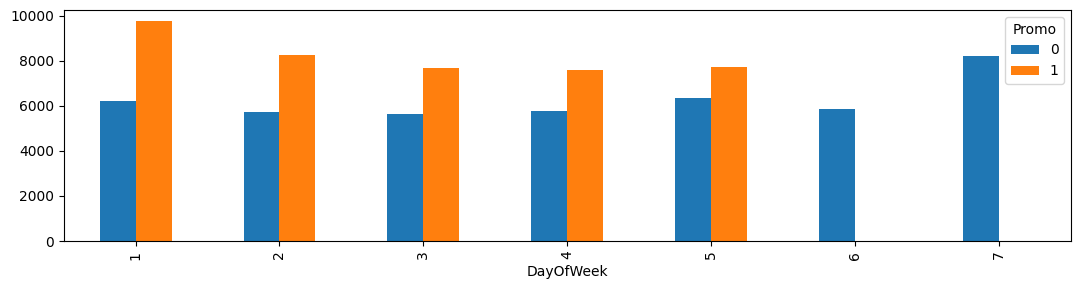

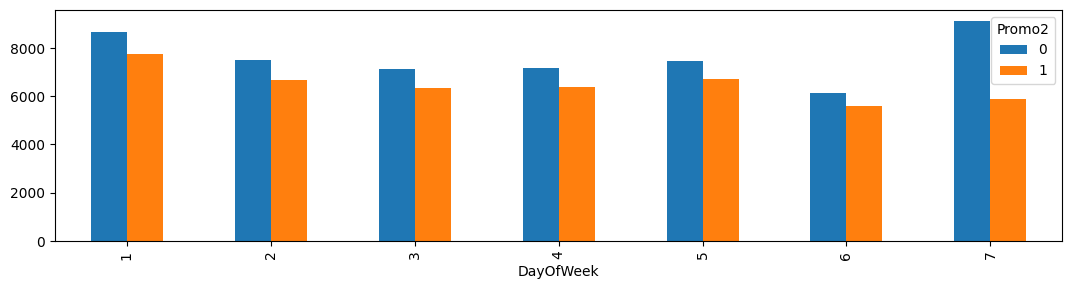

In [26]:
# Durchschnittlichen Umsatz nach Wochentagen und Promo / Promo2 über alle Filialen hinweg berechnen
umsatz_wochentag_promo = rossmann.groupby(['DayOfWeek', 'Promo'])['Sales'].mean().unstack()   # Unstack sorgt für eine übersichtlichere
umsatz_wochentag_promo2 = rossmann.groupby(['DayOfWeek', 'Promo2'])['Sales'].mean().unstack() #   Darstellung je Wochentag. Promo == 0 oder 1 wird als Tabelle dargestellt.
print(umsatz_wochentag_promo)
print(umsatz_wochentag_promo2)

# Visualisierung des Ergebnisses als Säulendiagramm
umsatz_wochentag_promo.plot(kind='bar', figsize=(13, 3))
umsatz_wochentag_promo2.plot(kind='bar', figsize=(13, 3))

*  Rabattaktionen (Promo) sorgen durchschnittlich Monatags für die größte Umsatzsteigerung.
*  Längerfristigige Rabattaktionen (Promo2) sorgen durchschnittlich Sonntags für den größten Umsatzeinbruch im Vergleich dazu, wenn keine längerfristigigen Rabattaktionen gemacht werden.

## FF2: Wie hängen Filialtyp, Sortiment und Entfernung zur Konkurrenz mit dem Umsatz und dem Umsatz pro Kunde zusammen?

### Einfluss der Filialtypen (a, b, c, d) auf den Umsatz und den Umsatz pro Kunde

StoreType
a     6925.682833
b    10232.722511
c     6933.126425
d     6822.300064
Name: Sales, dtype: float64


<Axes: xlabel='StoreType'>

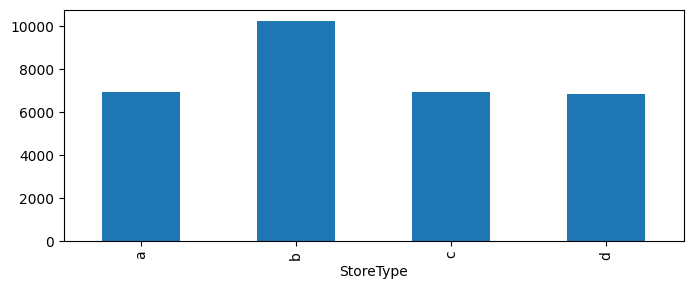

In [27]:
# Tabelle mit Mittelwerten für Umsatz (Sales) nach Filialtyp (StoreType)
umsatz_filialtyp = rossmann.groupby('StoreType')['Sales'].mean()
print(umsatz_filialtyp)

# Umsätze als Säulendiagramm darstellen
umsatz_filialtyp.plot(kind='bar', figsize=(8, 3))

*   Filialtyp b verzeichnet mit Abstand den höchsten durchschnittlichen Umsatz, während die Filialtypen a, c & d jeweils nahezu dieselben durchschnittlichen Umsätze erzielen.

StoreType
a     8.846277
b     5.133097
c     8.626227
d    11.277862
Name: SalesPerCustomer, dtype: float64


<Axes: xlabel='StoreType'>

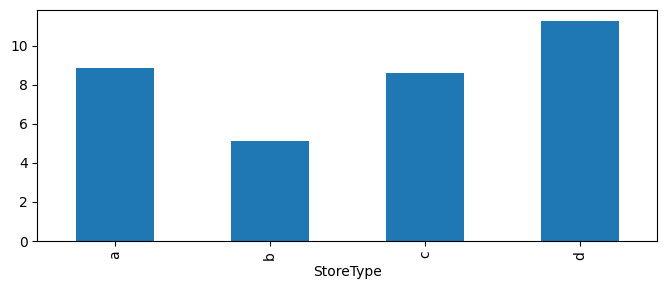

In [28]:
# Tabelle mit Mittelwerten für Umsatz pro Kunde (SalesPerCustomer) nach Filialtyp (StoreType)
umsatz_filialtyp_pro_kunde = rossmann.groupby('StoreType')['SalesPerCustomer'].mean()
print(umsatz_filialtyp_pro_kunde)

# Umsätze pro Kunde als Säulendiagramm darstellen
umsatz_filialtyp_pro_kunde.plot(kind='bar', figsize=(8, 3))

*   Im Gegensatz dazu verzeichnet Filialtyp b den niedrigsten durchschnittlichen Umsatz pro Kunde und Filialtyp d den höchsten. Die Verteilung der durchschnittlichen Umsätze pro Kunde ist über die verschiedenen Filialtypen allerdings unregelmäßiger.

### Einfluss der Sortimentstypen (a = basic, b = extra, c = extended) auf den Umsatz und den Umsatz pro Kunde

Assortment
a    6621.508173
b    8641.450914
c    7300.843547
Name: Sales, dtype: float64


<Axes: xlabel='Assortment'>

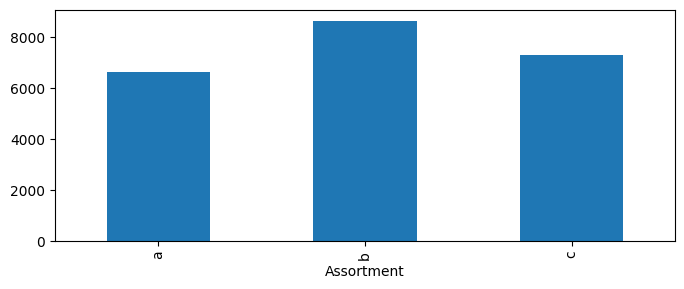

In [29]:
# Tabelle mit Mittelwerten für Umsatz (Sales) nach  Sortimentstyp (StoreType)
umsatz_sortiment = rossmann.groupby('Assortment')['Sales'].mean()
print(umsatz_sortiment)

# Umsätze als Säulendiagramm darstellen
umsatz_sortiment.plot(kind='bar', figsize=(8, 3))

*   Sortimentstyp b verzeichnet den höchsten durchschnittlichen Umsatz.

Assortment
a     9.130786
b     4.163219
c    10.018030
Name: SalesPerCustomer, dtype: float64


<Axes: xlabel='Assortment'>

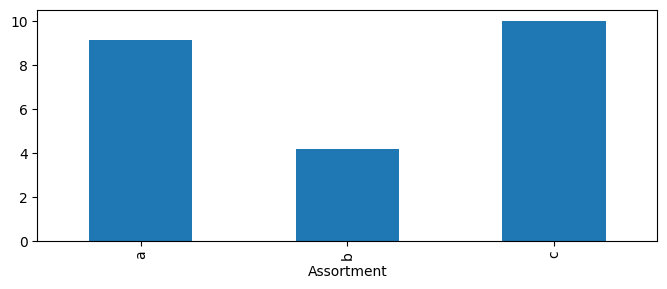

In [30]:
# Tabelle mit Mittelwerten für Umsatz pro Kunde (SalesPerCustomer) nach  Sortimentstyp (StoreType)
umsatz_sortiment_pro_kunde = rossmann.groupby('Assortment')['SalesPerCustomer'].mean()
print(umsatz_sortiment_pro_kunde)

# Umsätze pro Kunde als Säulendiagramm darstellen
umsatz_sortiment_pro_kunde.plot(kind='bar', figsize=(8, 3))

*   Im Gegensatz dazu verzeichnet Sortimentstyp b den niedrigsten durchschnittlichen Umsatz pro Kunde und Sortimentstyp c den höchsten.

### Einfluss der Konkurrenzentfernung auf den Umsatz und den Umsatz pro Kunde

-0.03590432877082352


<Axes: xlabel='CompetitionDistance', ylabel='Sales'>

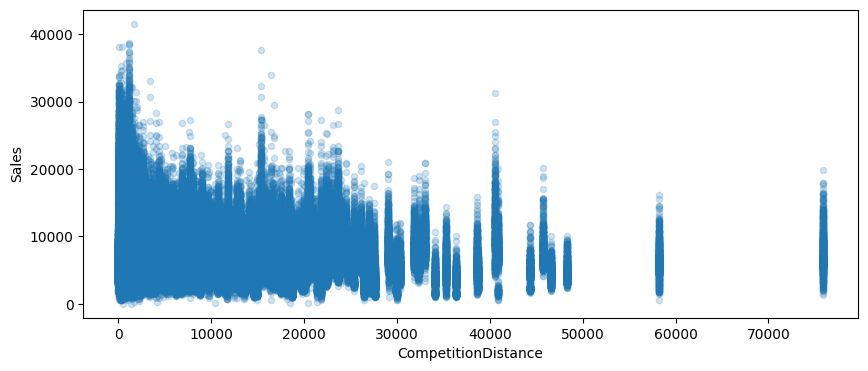

In [31]:
# Korrelation zwischen Entfernung zur Konkurrenz und Umsatz berechnen
korrelation_umsatz = rossmann['CompetitionDistance'].corr(rossmann['Sales'])
print(korrelation_umsatz)

# Streudiagramm (visuelle Korrelation): Entfernung zur Konkurrenz vs. Umsatz
rossmann.plot(kind='scatter', x='CompetitionDistance', y='Sales', alpha=0.2, figsize=(10, 4),)

*   Der Wert der Korrelation liegt fast exakt bei 0 (0,0359). Das bedeutet: Es gibt praktisch keinen Zusammenhang. Ob die Konkurrenz 100 Meter oder 10 Kilometer entfernt ist, hat über alle Filialen hinweg keinen direkten Einfluss auf die Höhe des Umsatzes.

0.205720862846727


<Axes: xlabel='CompetitionDistance', ylabel='SalesPerCustomer'>

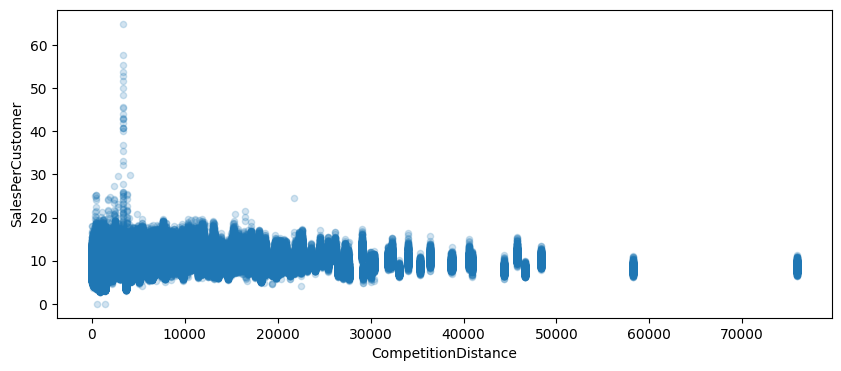

In [32]:
# Korrelation zwischen Entfernung zur Konkurrenz und Umsatz berechnen
korrelation_umsatz_pro_kunde = rossmann['CompetitionDistance'].corr(rossmann['SalesPerCustomer'])
print(korrelation_umsatz_pro_kunde)

# Streudiagramm (visuelle Korrelation): Entfernung zur Konkurrenz vs. Umsatz pro Kunde
rossmann.plot(kind='scatter', x='CompetitionDistance', y='SalesPerCustomer', alpha=0.2, figsize=(10, 4),)

*   Hier liegt ein schwacher positiver Zusammenhang vor. Das bedeutet: Wenn die Konkurrenz weiter entfernt ist, geben die Kunden pro Einkauf im Schnitt **etwas** mehr Geld aus.

## Fazit & Beantwortung der Forschungsfragen

Die Datenanalyse liefert klare Antworten auf die untersuchten Fragestellungen zur Umsatzsteuerung der Rossmann-Filialen:

*   Werbeaktionen & Wochentage (FF1): Kurzfristige Rabattaktionen (Promo) wirken als starker Umsatzhebel und steigern den Tagesumsatz um durchschnittlich +38,77 % (+2.298,87 €) mit dem höchsten Zuwachs am Montag. Dauerhafte Aktionen (Promo2) führen hingegen zu einem Umsatzrückgang von -10,77 % und erweisen sich als unrentabel.
*   Filialstruktur & Sortiment (FF2): Filialtyp b erzielt den höchsten Tagesumsatz (10.232,72 €), weist aber den geringsten Umsatz pro Kunde auf (5,13 €). Filialtyp d nutzt dagegen das beste Upselling-Potenzial mit 11,28 € pro Kunde. Beim Sortiment generiert die Kategorie b (extra) den höchsten Schnitt (8.641,45 €), gefolgt von c (extended) und a (basic).

### Kernerkenntnis: Zielgerichtete, zeitlich begrenzte Werbeimpulse und eine an den Filialtyp angepasste Sortimentstiefe sichern den höchsten Ertrag, während flächendeckende Dauerpromotionen die Marge belasten.